# Clasificación de glóbulos blancos con redes convolucionales

## 1. Problema y dataset

El conteo diferencial de glóbulos blancos (cuántos eosinófilos, linfocitos, monocitos y neutrófilos hay en una muestra) es parte de la biometría hemática y se usa para orientar el diagnóstico de infecciones, alergias y enfermedades de la sangre. Hacerlo a mano en el microscopio es lento y depende de la experiencia de quien lo hace. El objetivo del proyecto es clasificar automáticamente imágenes de frotis sanguíneo en los 4 tipos de glóbulo blanco.

Dataset: Blood Cell Images (Paul Mooney, Kaggle) - https://www.kaggle.com/datasets/paultimothymooney/blood-cells

In [1]:
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

In [2]:
data_dir = pathlib.Path("..") / "data" / "dataset2-master" / "images"
splits = ["TRAIN", "TEST", "TEST_SIMPLE"]
classes = sorted(os.listdir(data_dir / "TRAIN"))
classes

['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']

## 2. Distribución de imágenes por clase y por conjunto

In [3]:
counts = pd.DataFrame(
    {s: [len(os.listdir(data_dir / s / c)) for c in classes] for s in splits},
    index=classes,
)
counts.loc["Total"] = counts.sum()
counts

,TRAIN,TEST,TEST_SIMPLE
EOSINOPHIL,2497,623,13
LYMPHOCYTE,2483,620,6
MONOCYTE,2478,620,4
NEUTROPHIL,2499,624,48
Total,9957,2487,71


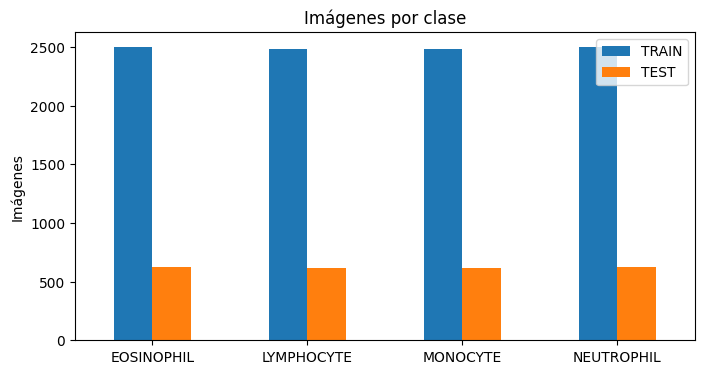

In [4]:
counts.drop("Total")[["TRAIN", "TEST"]].plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Imágenes")
plt.title("Imágenes por clase")
plt.show()

TRAIN y TEST están balanceados, con alrededor de 2,500 y 620 imágenes por clase. TEST_SIMPLE es distinto: tiene 71 imágenes sin aumentar y está muy desbalanceado (48 neutrófilos y solo 4 monocitos).

## 3. Tamaño y formato de las imágenes

In [5]:
sizes = {}
for s in ["TRAIN", "TEST"]:
    for c in classes:
        for f in os.listdir(data_dir / s / c)[:200]:
            img = keras.utils.load_img(data_dir / s / c / f)
            sizes[img.size] = sizes.get(img.size, 0) + 1
sizes

{(320, 240): 1600}

In [6]:
sample = keras.utils.img_to_array(keras.utils.load_img(data_dir / "TRAIN" / classes[0] / os.listdir(data_dir / "TRAIN" / classes[0])[0]))
sample.shape, sample.min(), sample.max()

((240, 320, 3), np.float32(0.0), np.float32(255.0))

Todas las imágenes son RGB de 320x240 con valores entre 0 y 255. Para el modelo habrá que reescalarlas a [0, 1] y reducir su tamaño para que el entrenamiento sea manejable.

## 4. Ejemplos por clase

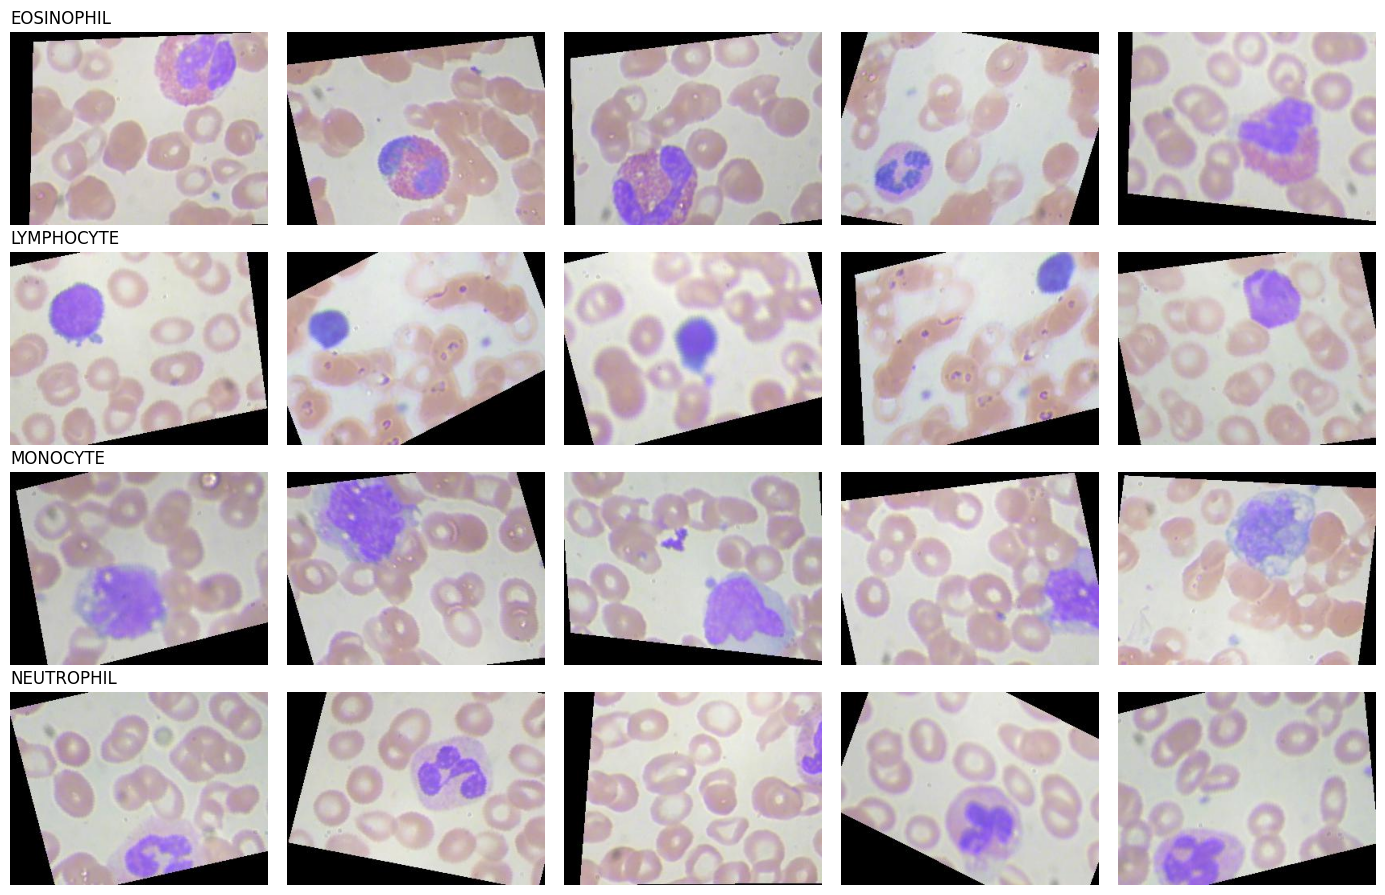

In [7]:
np.random.seed(42)
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 9))
for i, c in enumerate(classes):
    files = np.random.choice(os.listdir(data_dir / "TRAIN" / c), 5, replace=False)
    for j, f in enumerate(files):
        axes[i, j].imshow(keras.utils.load_img(data_dir / "TRAIN" / c / f))
        axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left")
plt.tight_layout()
plt.show()

Cada imagen tiene un glóbulo blanco (teñido de morado) rodeado de glóbulos rojos. La diferencia entre clases está en la forma del núcleo: el linfocito tiene un núcleo redondo que ocupa casi toda la célula, el monocito un núcleo grande en forma de riñón, el neutrófilo un núcleo segmentado en varios lóbulos y el eosinófilo un núcleo de dos lóbulos con gránulos. Eosinófilo y neutrófilo son los que más se parecen entre sí.

## 5. Originales y versiones aumentadas

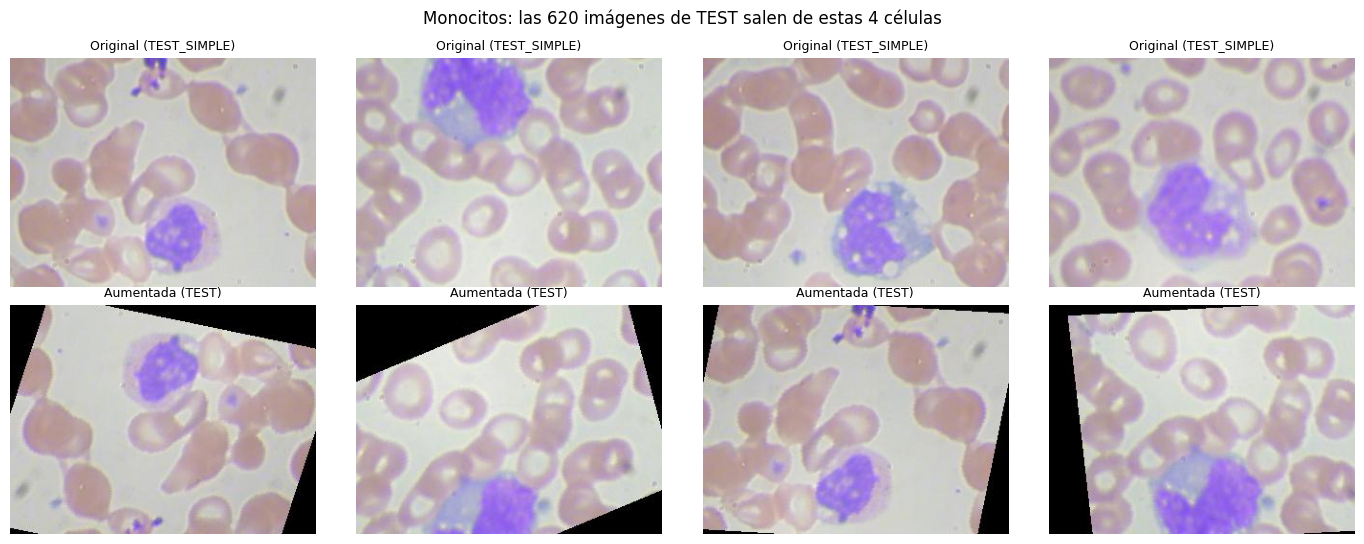

In [8]:
originals = sorted(os.listdir(data_dir / "TEST_SIMPLE" / "MONOCYTE"))
augmented = np.random.choice(os.listdir(data_dir / "TEST" / "MONOCYTE"), 4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for j, f in enumerate(originals):
    axes[0, j].imshow(keras.utils.load_img(data_dir / "TEST_SIMPLE" / "MONOCYTE" / f))
    axes[0, j].set_title("Original (TEST_SIMPLE)", fontsize=9)
for j, f in enumerate(augmented):
    axes[1, j].imshow(keras.utils.load_img(data_dir / "TEST" / "MONOCYTE" / f))
    axes[1, j].set_title("Aumentada (TEST)", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Monocitos: las 620 imágenes de TEST salen de estas 4 células")
plt.tight_layout()
plt.show()

Las imágenes de TRAIN y TEST no son fotos independientes: son versiones aumentadas (rotadas, desplazadas y volteadas) de un número pequeño de fotos originales. Por eso aparecen bordes negros en muchas imágenes. TEST sale de las 71 originales de TEST_SIMPLE, así que solo 4 monocitos distintos y 6 linfocitos distintos se repiten más de 100 veces cada uno.

Consecuencias para el modelado:
- TRAIN y TEST no comparten células, así que TEST sí mide la generalización a células nuevas.
- El accuracy en TEST va a ser bastante más bajo que en TRAIN, porque el modelo se evalúa con muy pocas células distintas de cada clase.
- Si el set de validación se saca al azar de TRAIN, va a tener copias aumentadas de las mismas células que el entrenamiento y su accuracy saldrá inflado. Hay que tomarlo en cuenta al analizar las curvas de entrenamiento.